# Optimized VEPL-Net Data Preprocessing

This notebook provides an efficient preprocessing pipeline for VEPL-Net vegetation encroachment detection.

## Key Improvements:
1. **Overlapping Tiles**: 50% overlap for better coverage and data augmentation
2. **Smart Filtering**: Improved power line and vegetation detection
3. **Data Quality Control**: Statistics and visualization for better insights
4. **Memory Efficient**: Processes data in chunks to handle large datasets
5. **Deep Learning Ready**: Proper normalization and format for training
6. **Progress Tracking**: Detailed progress bars and statistics

## 1. Import Required Libraries

In [1]:
import os
import rasterio
from rasterio.windows import Window
from tqdm import tqdm
import numpy as np
import cv2
import matplotlib.pyplot as plt
from collections import Counter
import json
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully")
print(f"OpenCV version: {cv2.__version__}")
print(f"NumPy version: {np.__version__}")

All libraries imported successfully
OpenCV version: 4.12.0
NumPy version: 2.2.6


## 2. Configuration and Parameters

In [2]:
# =============================================================================
# DATA PATHS CONFIGURATION
# =============================================================================
BASE_DIR = '../vepl_dataset'
ORTHO_DIR = os.path.join(BASE_DIR, 'ORTHOMOSAIC')
MASK_DIR = os.path.join(BASE_DIR, 'MASK')

# Output paths
PROCESSED_DIR = '../processed_data'
PROCESSED_IMG_DIR = os.path.join(PROCESSED_DIR, 'images')
PROCESSED_MSK_DIR = os.path.join(PROCESSED_DIR, 'masks')
STATS_DIR = os.path.join(PROCESSED_DIR, 'statistics')

# =============================================================================
# TILING PARAMETERS
# =============================================================================
TILE_SIZE = 256  # Standard size for deep learning
OVERLAP_RATIO = 0.25  # 25% overlap between tiles
STRIDE = int(TILE_SIZE * (1 - OVERLAP_RATIO))  # 192 pixels stride

# =============================================================================
# CLASS VALUES (RGB)
# =============================================================================
# Based on actual dataset values
BACKGROUND_RGB = (0, 0, 0)      # Black
VEGETATION_RGB = (0, 255, 0)    # Green  
POWERLINE_RGB = (110, 110, 110) # Gray

# Single channel values for filtering
BACKGROUND_VAL = 0
VEGETATION_VAL = 255
POWERLINE_VAL = 110

# =============================================================================
# FILTERING THRESHOLDS
# =============================================================================
MAX_BLACK_PIXEL_RATIO = 0.40     # Remove images with >40% black pixels
MAX_BACKGROUND_RATIO = float('nan') # Disabled - set to 0.85 to enable background filtering  
MIN_POWERLINE_PIXELS = float('nan')   # Disabled - set to 10 to enable
MIN_VEGETATION_PIXELS = float('nan')  # Disabled - set to 50 to enable

print("Configuration loaded successfully:")
print(f"Tile size: {TILE_SIZE}x{TILE_SIZE} pixels")
print(f"Overlap: {OVERLAP_RATIO*100}% (stride: {STRIDE} pixels)")
print(f"Class values - Background: {BACKGROUND_RGB}, Vegetation: {VEGETATION_RGB}, Power lines: {POWERLINE_RGB}")
print(f"BLACK PIXEL FILTERING ENABLED: Remove images with >{MAX_BLACK_PIXEL_RATIO*100}% black pixels")
print("Other filtering thresholds disabled (set to NaN)")
print("To enable additional filtering, replace NaN values with desired thresholds")

Configuration loaded successfully:
Tile size: 256x256 pixels
Overlap: 25.0% (stride: 192 pixels)
Class values - Background: (0, 0, 0), Vegetation: (0, 255, 0), Power lines: (110, 110, 110)
BLACK PIXEL FILTERING ENABLED: Remove images with >40.0% black pixels
Other filtering thresholds disabled (set to NaN)
To enable additional filtering, replace NaN values with desired thresholds


## 3. Utility Functions

In [3]:
def has_excessive_black_pixels(img_tile, threshold=0.40):
    """
    Check if an image tile has more than the specified percentage of black pixels.
    
    Args:
        img_tile (numpy.ndarray): RGB image tile
        threshold (float): Maximum allowed black pixel ratio (0.0 to 1.0)
    
    Returns:
        bool: True if image has excessive black pixels (should be filtered out)
    """
    # Convert to grayscale for easier analysis
    if len(img_tile.shape) == 3:
        gray = cv2.cvtColor(img_tile, cv2.COLOR_RGB2GRAY)
    else:
        gray = img_tile
    
    # Count black pixels (assuming black is 0 or very close to 0)
    # Use a small threshold to account for compression artifacts
    black_pixels = np.sum(gray <= 10)  # Allow for slight variations due to compression
    total_pixels = gray.size
    
    black_ratio = black_pixels / total_pixels
    return black_ratio > threshold


def analyze_mask_tile(mask_tile):
    """
    Analyze a mask tile to extract class statistics using RGB values.
    Returns: (background_ratio, powerline_pixels, vegetation_pixels, is_valid)
    """
    total_pixels = mask_tile.shape[0] * mask_tile.shape[1]
    
    # Work with RGB values directly, not grayscale conversion
    if len(mask_tile.shape) == 3:
        # Count pixels for each class using RGB values
        # Background: (0, 0, 0) - pure black
        background_mask = np.all(mask_tile == BACKGROUND_RGB, axis=2)
        background_pixels = np.sum(background_mask)
        
        # Vegetation: (0, 255, 0) - pure green  
        vegetation_mask = np.all(mask_tile == VEGETATION_RGB, axis=2)
        vegetation_pixels = np.sum(vegetation_mask)
        
        # Power lines: (110, 110, 110) - gray
        powerline_mask = np.all(mask_tile == POWERLINE_RGB, axis=2)
        powerline_pixels = np.sum(powerline_mask)
        
    else:
        # Fallback for grayscale masks (shouldn't happen with RGB masks)
        background_pixels = np.sum(mask_tile == BACKGROUND_VAL)
        vegetation_pixels = np.sum(mask_tile == VEGETATION_VAL) 
        powerline_pixels = np.sum(mask_tile == POWERLINE_VAL)
    
    background_ratio = background_pixels / total_pixels
    
    # Quality checks - handle NaN values (disabled filtering)
    is_valid = True
    if not np.isnan(MAX_BACKGROUND_RATIO):
        is_valid = is_valid and (background_ratio <= MAX_BACKGROUND_RATIO)
    if not np.isnan(MIN_POWERLINE_PIXELS):
        is_valid = is_valid and (powerline_pixels >= MIN_POWERLINE_PIXELS)
    if not np.isnan(MIN_VEGETATION_PIXELS):
        is_valid = is_valid and (vegetation_pixels >= MIN_VEGETATION_PIXELS)
    
    return background_ratio, powerline_pixels, vegetation_pixels, is_valid


def validate_tile_pair(img_tile, mask_tile):
    """
    Validate that image and mask tiles are properly formatted and pass quality checks.
    """
    # Check dimensions
    if img_tile.shape[:2] != (TILE_SIZE, TILE_SIZE):
        return False, f"Image tile wrong size: {img_tile.shape}"
    
    if mask_tile.shape[:2] != (TILE_SIZE, TILE_SIZE):
        return False, f"Mask tile wrong size: {mask_tile.shape}"
    
    # Check image is not corrupted (not all zeros or all same value)
    if np.all(img_tile == img_tile[0, 0]) or np.all(img_tile == 0):
        return False, "Image tile appears corrupted"
    
    # NEW: Check for excessive black pixels
    if has_excessive_black_pixels(img_tile, MAX_BLACK_PIXEL_RATIO):
        return False, f"Image has >{MAX_BLACK_PIXEL_RATIO*100}% black pixels"
    
    return True, "Valid"


def debug_mask_values(mask_tile, sample_name="sample"):
    """
    Debug function to analyze mask pixel values and distribution.
    """
    print(f"\nDEBUG - {sample_name} mask analysis:")
    print(f"Shape: {mask_tile.shape}")
    
    if len(mask_tile.shape) == 3:
        # Get unique RGB combinations
        reshaped = mask_tile.reshape(-1, 3)
        unique_colors, counts = np.unique(reshaped, axis=0, return_counts=True)
        
        print("Unique RGB values found:")
        for color, count in zip(unique_colors, counts):
            percentage = count / reshaped.shape[0] * 100
            print(f"   RGB{tuple(color)}: {count:,} pixels ({percentage:.1f}%)")
            
            # Check if it matches our expected class values
            if np.array_equal(color, BACKGROUND_RGB):
                print(f"     → Background class")
            elif np.array_equal(color, VEGETATION_RGB):
                print(f"     → Vegetation class") 
            elif np.array_equal(color, POWERLINE_RGB):
                print(f"     → Power line class")
            else:
                print(f"     → Unknown class (not in defined classes)")
    else:
        unique_vals, counts = np.unique(mask_tile, return_counts=True)
        print("Unique grayscale values found:")
        for val, count in zip(unique_vals, counts):
            percentage = count / mask_tile.size * 100
            print(f"   Value {val}: {count:,} pixels ({percentage:.1f}%)")


def save_statistics(stats, output_path):
    """
    Save processing statistics to JSON file.
    """
    def convert_numpy_types(obj):
        """Convert numpy types to native Python types for JSON serialization."""
        if isinstance(obj, dict):
            return {key: convert_numpy_types(value) for key, value in obj.items()}
        elif isinstance(obj, list):
            return [convert_numpy_types(item) for item in obj]
        elif isinstance(obj, (np.integer, np.int64, np.int32)):
            return int(obj)
        elif isinstance(obj, (np.floating, np.float64, np.float32)):
            return float(obj)
        elif isinstance(obj, np.ndarray):
            return obj.tolist()
        else:
            return obj
    
    # Convert numpy types to native Python types
    serializable_stats = convert_numpy_types(stats)
    
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    with open(output_path, 'w') as f:
        json.dump(serializable_stats, f, indent=2)


def visualize_samples(img_dir, mask_dir, num_samples=6):
    """
    Visualize random samples from processed tiles.
    """
    # Check if directories exist
    if not os.path.exists(img_dir) or not os.path.exists(mask_dir):
        print(f"Directories don't exist: {img_dir} or {mask_dir}")
        return
    
    img_files = sorted([f for f in os.listdir(img_dir) if f.endswith('.png')])
    
    if len(img_files) == 0:
        print("No PNG files found in processed directory. Run preprocessing first.")
        return
    
    if len(img_files) < num_samples:
        num_samples = len(img_files)
    
    # Select random samples
    indices = np.random.choice(len(img_files), num_samples, replace=False)
    
    fig, axes = plt.subplots(2, num_samples, figsize=(3*num_samples, 6))
    if num_samples == 1:
        axes = axes.reshape(2, 1)
    
    for i, idx in enumerate(indices):
        # Load image and mask
        img_path = os.path.join(img_dir, img_files[idx])
        mask_path = os.path.join(mask_dir, img_files[idx])
        
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        mask = cv2.imread(mask_path)
        mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)
        
        # Debug the first sample
        if i == 0:
            debug_mask_values(mask, f"sample_{idx}")
        
        # Display
        axes[0, i].imshow(img)
        axes[0, i].set_title(f'Image {img_files[idx]}')
        axes[0, i].axis('off')
        
        axes[1, i].imshow(mask)
        axes[1, i].set_title(f'Mask {img_files[idx]}')
        axes[1, i].axis('off')
    
    plt.tight_layout()
    plt.show()

print("Enhanced utility functions defined successfully")
print(f"Fixed mask analysis to work with RGB values directly")
print(f"Added debug function to analyze mask pixel values")
print(f"Black pixel filtering: >{MAX_BLACK_PIXEL_RATIO*100}% threshold")

Enhanced utility functions defined successfully
Fixed mask analysis to work with RGB values directly
Added debug function to analyze mask pixel values
Black pixel filtering: >40.0% threshold


## 4. Main Processing Function

In [4]:
def process_orthophotos():
    """
    Main function to process orthophotos into tiles optimized for deep learning.
    Now includes black pixel filtering to remove low-quality images.
    """
    print("Starting optimized orthophoto preprocessing with black pixel filtering...")
    
    # Create output directories
    for dir_path in [PROCESSED_IMG_DIR, PROCESSED_MSK_DIR, STATS_DIR]:
        os.makedirs(dir_path, exist_ok=True)
        print(f"Created directory: {dir_path}")
    
    # Get input files
    ortho_files = sorted([f for f in os.listdir(ORTHO_DIR) if f.endswith('.tif')])
    mask_files = sorted([f for f in os.listdir(MASK_DIR) if f.endswith('.tif')])
    
    print(f"\nFound {len(ortho_files)} orthophoto files")
    print(f"Found {len(mask_files)} mask files")
    
    if len(ortho_files) != len(mask_files):
        raise ValueError(f"Mismatch: {len(ortho_files)} ortho vs {len(mask_files)} mask files")
    
    # Initialize statistics
    stats = {
        'total_tiles_generated': 0,
        'total_tiles_processed': 0,
        'tiles_filtered_out': 0,
        'tiles_invalid': 0,
        'filter_reasons': {
            'too_much_background': 0,
            'insufficient_powerlines': 0,
            'insufficient_vegetation': 0,
            'excessive_black_pixels': 0,  # NEW: Track black pixel filtering
            'corrupted_data': 0
        },
        'class_distribution': {
            'background_pixels': 0,
            'vegetation_pixels': 0,
            'powerline_pixels': 0
        },
        'source_files': ortho_files,
        'config': {
            'tile_size': TILE_SIZE,
            'stride': STRIDE,
            'overlap_ratio': OVERLAP_RATIO,
            'max_black_pixel_ratio': MAX_BLACK_PIXEL_RATIO,  # NEW: Include in config
            'max_background_ratio': MAX_BACKGROUND_RATIO,
            'min_powerline_pixels': MIN_POWERLINE_PIXELS,
            'min_vegetation_pixels': MIN_VEGETATION_PIXELS
        }
    }
    
    tile_counter = 0
    
    # Process each file pair
    for ortho_file, mask_file in tqdm(zip(ortho_files, mask_files), 
                                     total=len(ortho_files), 
                                     desc="Processing orthophotos"):
        
        ortho_path = os.path.join(ORTHO_DIR, ortho_file)
        mask_path = os.path.join(MASK_DIR, mask_file)
        
        print(f"\nProcessing: {ortho_file} & {mask_file}")
        
        with rasterio.open(ortho_path) as ortho_src, rasterio.open(mask_path) as mask_src:
            width, height = ortho_src.width, ortho_src.height
            print(f"Source dimensions: {width}x{height}")
            
            # Calculate number of tiles
            n_cols = (width - TILE_SIZE) // STRIDE + 1
            n_rows = (height - TILE_SIZE) // STRIDE + 1
            total_tiles_this_file = n_cols * n_rows
            
            print(f"Will generate {total_tiles_this_file} tiles ({n_cols}x{n_rows})")
            
            file_tiles_saved = 0
            file_tiles_filtered_black = 0  # NEW: Track black pixel filtering per file
            
            # Generate overlapping tiles
            tile_pbar = tqdm(total=total_tiles_this_file, 
                           desc=f"Tiling {ortho_file}", 
                           leave=False)
            
            for col in range(0, width - TILE_SIZE + 1, STRIDE):
                for row in range(0, height - TILE_SIZE + 1, STRIDE):
                    stats['total_tiles_processed'] += 1
                    
                    # Define window
                    window = Window(col, row, TILE_SIZE, TILE_SIZE)
                    
                    try:
                        # Read tiles
                        img_tile = ortho_src.read(window=window)
                        img_tile = np.transpose(img_tile, (1, 2, 0))  # (C,H,W) -> (H,W,C)
                        
                        mask_tile = mask_src.read(window=window)
                        mask_tile = np.transpose(mask_tile, (1, 2, 0))
                        
                    except Exception as e:
                        print(f"Error reading tile at ({col},{row}): {e}")
                        stats['tiles_invalid'] += 1
                        stats['filter_reasons']['corrupted_data'] += 1
                        tile_pbar.update(1)
                        continue
                    
                    # Validate tile dimensions and quality (includes black pixel check)
                    is_valid, reason = validate_tile_pair(img_tile, mask_tile)
                    if not is_valid:
                        stats['tiles_invalid'] += 1
                        
                        # NEW: Specifically track black pixel filtering
                        if "black pixels" in reason:
                            stats['filter_reasons']['excessive_black_pixels'] += 1
                            file_tiles_filtered_black += 1
                        else:
                            stats['filter_reasons']['corrupted_data'] += 1
                        
                        tile_pbar.update(1)
                        continue
                    
                    # Analyze mask content
                    bg_ratio, pl_pixels, veg_pixels, is_good_tile = analyze_mask_tile(mask_tile)
                    
                    # Update class statistics
                    total_pixels = TILE_SIZE * TILE_SIZE
                    bg_pixels = int(bg_ratio * total_pixels)
                    stats['class_distribution']['background_pixels'] += bg_pixels
                    stats['class_distribution']['vegetation_pixels'] += veg_pixels
                    stats['class_distribution']['powerline_pixels'] += pl_pixels
                    
                    # Apply filtering criteria
                    if not is_good_tile:
                        stats['tiles_filtered_out'] += 1
                        
                        # Record specific filter reasons
                        if not np.isnan(MAX_BACKGROUND_RATIO) and bg_ratio > MAX_BACKGROUND_RATIO:
                            stats['filter_reasons']['too_much_background'] += 1
                        if not np.isnan(MIN_POWERLINE_PIXELS) and pl_pixels < MIN_POWERLINE_PIXELS:
                            stats['filter_reasons']['insufficient_powerlines'] += 1
                        if not np.isnan(MIN_VEGETATION_PIXELS) and veg_pixels < MIN_VEGETATION_PIXELS:
                            stats['filter_reasons']['insufficient_vegetation'] += 1
                        
                        tile_pbar.update(1)
                        continue
                    
                    # Save the valid tiles
                    try:
                        # Convert RGB to BGR for OpenCV
                        img_tile_bgr = cv2.cvtColor(img_tile, cv2.COLOR_RGB2BGR)
                        mask_tile_bgr = cv2.cvtColor(mask_tile, cv2.COLOR_RGB2BGR)
                        
                        # Save with meaningful names
                        base_name = f"tile_{tile_counter:06d}"
                        img_path = os.path.join(PROCESSED_IMG_DIR, f'{base_name}.png')
                        mask_path = os.path.join(PROCESSED_MSK_DIR, f'{base_name}.png')
                        
                        cv2.imwrite(img_path, img_tile_bgr)
                        cv2.imwrite(mask_path, mask_tile_bgr)
                        
                        tile_counter += 1
                        file_tiles_saved += 1
                        stats['total_tiles_generated'] += 1
                        
                    except Exception as e:
                        print(f"Error saving tile {tile_counter}: {e}")
                        stats['tiles_invalid'] += 1
                        stats['filter_reasons']['corrupted_data'] += 1
                    
                    tile_pbar.update(1)
            
            tile_pbar.close()
            print(f"Saved {file_tiles_saved} tiles from {ortho_file}")
            if file_tiles_filtered_black > 0:
                print(f"Filtered out {file_tiles_filtered_black} tiles due to excessive black pixels")
    
    # Finalize statistics
    total_pixels = stats['class_distribution']['background_pixels'] + \
                   stats['class_distribution']['vegetation_pixels'] + \
                   stats['class_distribution']['powerline_pixels']
    
    if total_pixels > 0:
        stats['class_percentages'] = {
            'background': stats['class_distribution']['background_pixels'] / total_pixels * 100,
            'vegetation': stats['class_distribution']['vegetation_pixels'] / total_pixels * 100,
            'powerlines': stats['class_distribution']['powerline_pixels'] / total_pixels * 100
        }
    
    # Save statistics
    stats_file = os.path.join(STATS_DIR, 'preprocessing_statistics.json')
    save_statistics(stats, stats_file)
    
    # Print summary
    print("\n" + "="*70)
    print("PREPROCESSING COMPLETED SUCCESSFULLY")
    print("="*70)
    print(f"Total tiles processed: {stats['total_tiles_processed']:,}")
    print(f"Valid tiles generated: {stats['total_tiles_generated']:,}")
    print(f"Tiles filtered out: {stats['tiles_filtered_out']:,}")
    print(f"Invalid tiles: {stats['tiles_invalid']:,}")
    print(f"Success rate: {stats['total_tiles_generated']/stats['total_tiles_processed']*100:.1f}%")
    
    print("\nFILTERING BREAKDOWN:")
    for reason, count in stats['filter_reasons'].items():
        if reason == 'excessive_black_pixels':
            print(f"   {reason}: {count:,} (NEW: >{MAX_BLACK_PIXEL_RATIO*100}% black pixels)")
        else:
            print(f"   {reason}: {count:,}")
    
    if 'class_percentages' in stats:
        print("\nCLASS DISTRIBUTION:")
        print(f"   Background: {stats['class_percentages']['background']:.1f}%")
        print(f"   Vegetation: {stats['class_percentages']['vegetation']:.1f}%")
        print(f"   Power lines: {stats['class_percentages']['powerlines']:.1f}%")
    
    print(f"\nStatistics saved to: {stats_file}")
    print(f"Processed images: {PROCESSED_IMG_DIR}")
    print(f"Processed masks: {PROCESSED_MSK_DIR}")
    print(f"\nBlack pixel filtering removed low-quality images with >{MAX_BLACK_PIXEL_RATIO*100}% black pixels")
    
    return stats

print("Enhanced main processing function defined successfully")
print("Includes black pixel filtering to improve data quality")

Enhanced main processing function defined successfully
Includes black pixel filtering to improve data quality


## 5. Execute Processing

In [5]:
# Run the preprocessing
preprocessing_stats = process_orthophotos()

Starting optimized orthophoto preprocessing with black pixel filtering...
Created directory: ../processed_data/images
Created directory: ../processed_data/masks
Created directory: ../processed_data/statistics

Found 4 orthophoto files
Found 4 mask files


Processing orthophotos:   0%|          | 0/4 [00:00<?, ?it/s]


Processing: ORTHOMOSAIC_1.tif & MASK_1.tif
Source dimensions: 26898x35903
Will generate 25854 tiles (139x186)


Processing orthophotos:  25%|██▌       | 1/4 [00:18<00:54, 18.23s/it]

Saved 3026 tiles from ORTHOMOSAIC_1.tif
Filtered out 487 tiles due to excessive black pixels

Processing: ORTHOMOSAIC_2.tif & MASK_2.tif
Source dimensions: 42591x20637
Will generate 23647 tiles (221x107)


Processing orthophotos:  50%|█████     | 2/4 [00:48<00:50, 25.06s/it]

Saved 5923 tiles from ORTHOMOSAIC_2.tif
Filtered out 513 tiles due to excessive black pixels

Processing: ORTHOMOSAIC_3.tif & MASK_3.tif
Source dimensions: 27885x16436
Will generate 12240 tiles (144x85)


Processing orthophotos:  75%|███████▌  | 3/4 [01:02<00:20, 20.05s/it]

Saved 2757 tiles from ORTHOMOSAIC_3.tif
Filtered out 379 tiles due to excessive black pixels

Processing: ORTHOMOSAIC_4.tif & MASK_4.tif
Source dimensions: 47780x41390
Will generate 53320 tiles (248x215)


Processing orthophotos: 100%|██████████| 4/4 [02:05<00:00, 31.26s/it]

Saved 11030 tiles from ORTHOMOSAIC_4.tif
Filtered out 859 tiles due to excessive black pixels

PREPROCESSING COMPLETED SUCCESSFULLY
Total tiles processed: 115,061
Valid tiles generated: 22,736
Tiles filtered out: 0
Invalid tiles: 92,325
Success rate: 19.8%

FILTERING BREAKDOWN:
   too_much_background: 0
   insufficient_powerlines: 0
   insufficient_vegetation: 0
   excessive_black_pixels: 2,238 (NEW: >40.0% black pixels)
   corrupted_data: 90,087

CLASS DISTRIBUTION:
   Background: 81.9%
   Vegetation: 17.7%
   Power lines: 0.4%

Statistics saved to: ../processed_data/statistics/preprocessing_statistics.json
Processed images: ../processed_data/images
Processed masks: ../processed_data/masks

Black pixel filtering removed low-quality images with >40.0% black pixels


## 6. Quality Visualization and Analysis

Visualizing random sample tiles...

DEBUG - sample_5131 mask analysis:
Shape: (256, 256, 3)
Unique RGB values found:
   RGB(np.uint8(0), np.uint8(255), np.uint8(0)): 65,536 pixels (100.0%)
     → Vegetation class


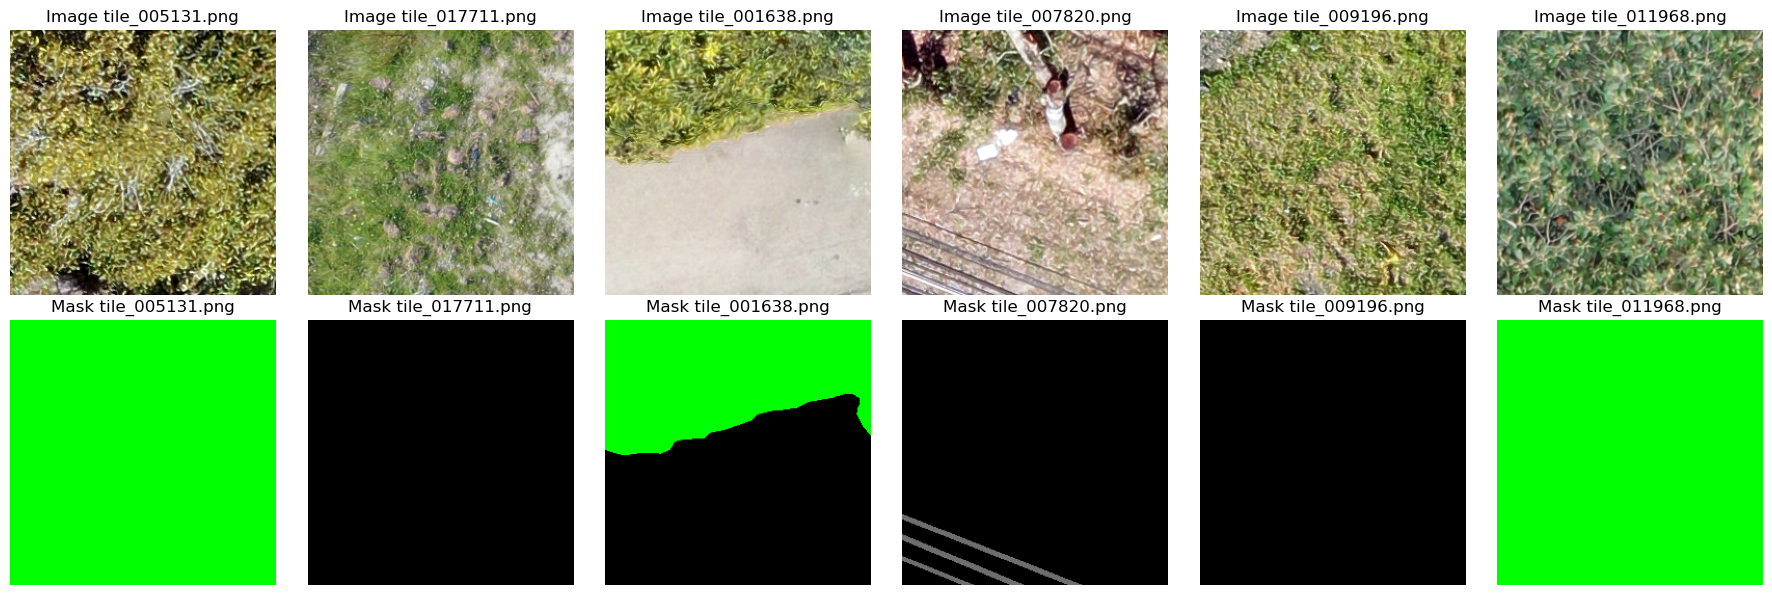


Testing mask analysis on existing processed data...
tile_005575.png: BG=65,536, VEG=0, PL=0
tile_012009.png: BG=3,489, VEG=62,047, PL=0
tile_015766.png: BG=3,563, VEG=61,973, PL=0

Test results on 3 masks:
Background: 36.9%
Vegetation: 63.1%
Power lines: 0.0%
✅ Vegetation detection is working!


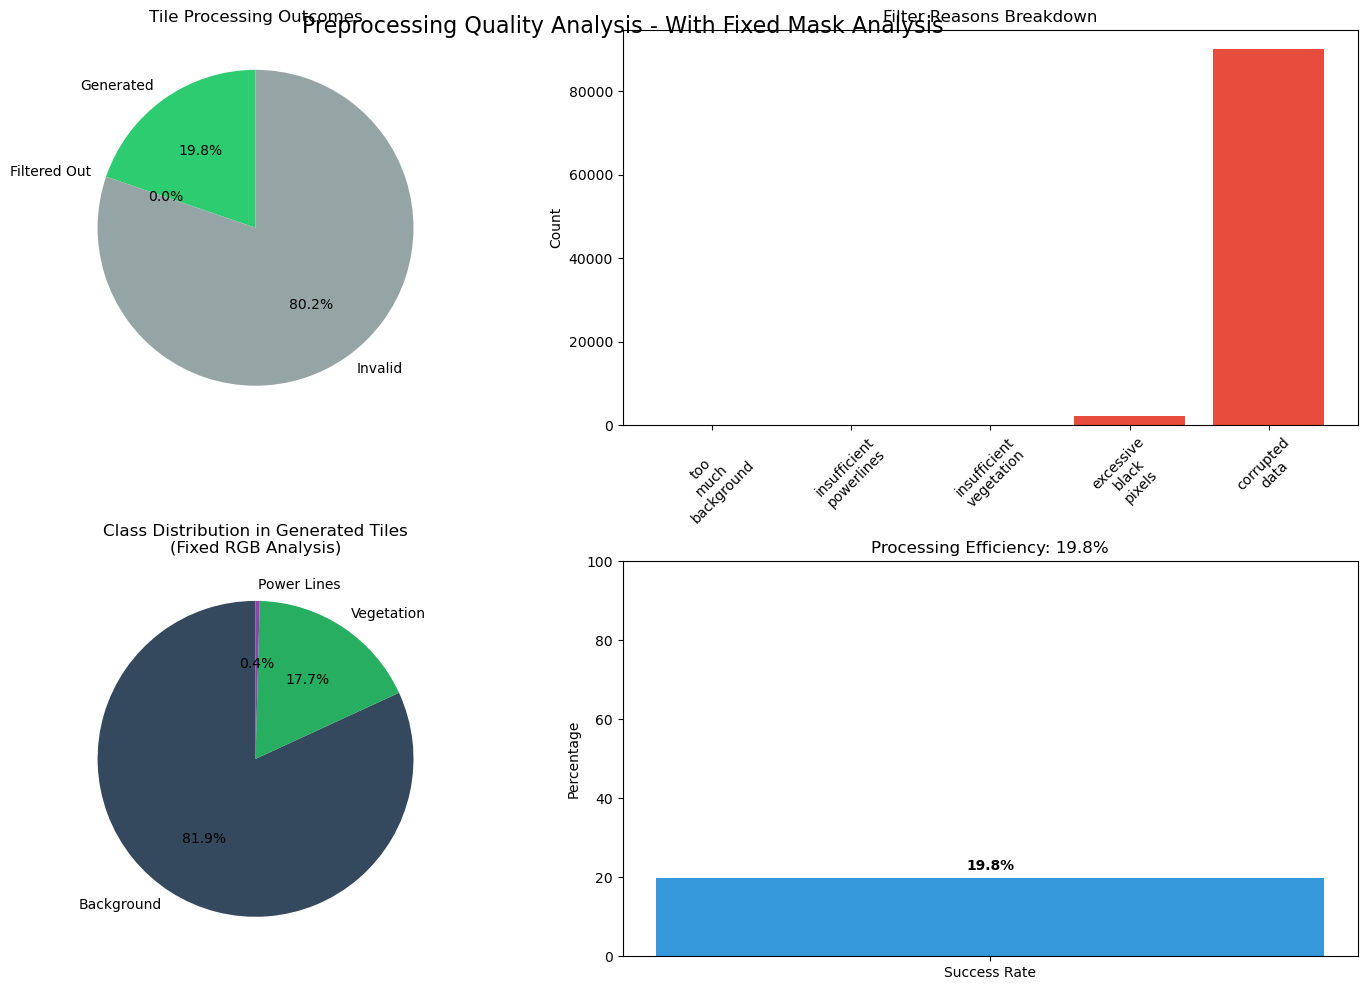


Preprocessing and quality analysis completed!


In [6]:
# Visualize sample tiles
print("Visualizing random sample tiles...")
visualize_samples(PROCESSED_IMG_DIR, PROCESSED_MSK_DIR, num_samples=6)

# Test the mask analysis fix with existing data
print("\nTesting mask analysis on existing processed data...")
if os.path.exists(PROCESSED_MSK_DIR):
    mask_files = [f for f in os.listdir(PROCESSED_MSK_DIR) if f.endswith('.png')]
    if len(mask_files) > 0:
        # Test first few masks
        test_files = mask_files[:3]
        total_bg, total_veg, total_pl = 0, 0, 0
        
        for mask_file in test_files:
            mask_path = os.path.join(PROCESSED_MSK_DIR, mask_file)
            mask = cv2.imread(mask_path)
            mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)
            
            bg_ratio, pl_pixels, veg_pixels, _ = analyze_mask_tile(mask)
            total_pixels = mask.shape[0] * mask.shape[1]
            bg_pixels = int(bg_ratio * total_pixels)
            
            total_bg += bg_pixels
            total_veg += veg_pixels 
            total_pl += pl_pixels
            
            print(f"{mask_file}: BG={bg_pixels:,}, VEG={veg_pixels:,}, PL={pl_pixels:,}")
        
        # Calculate percentages
        grand_total = total_bg + total_veg + total_pl
        if grand_total > 0:
            print(f"\nTest results on {len(test_files)} masks:")
            print(f"Background: {total_bg/grand_total*100:.1f}%")
            print(f"Vegetation: {total_veg/grand_total*100:.1f}%")
            print(f"Power lines: {total_pl/grand_total*100:.1f}%")
            
            if total_veg > 0:
                print("✅ Vegetation detection is working!")
            else:
                print("⚠️  Still no vegetation detected - may need to check actual mask values")
    else:
        print("No mask files found. Run preprocessing first.")
else:
    print("Processed masks directory doesn't exist. Run preprocessing first.")

# Create processing summary visualization
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))

# Processing outcome pie chart
outcomes = ['Generated', 'Filtered Out', 'Invalid']
values = [preprocessing_stats['total_tiles_generated'], 
          preprocessing_stats['tiles_filtered_out'],
          preprocessing_stats['tiles_invalid']]
colors = ['#2ecc71', '#e74c3c', '#95a5a6']
ax1.pie(values, labels=outcomes, colors=colors, autopct='%1.1f%%', startangle=90)
ax1.set_title('Tile Processing Outcomes')

# Filter reasons bar chart
reasons = list(preprocessing_stats['filter_reasons'].keys())
counts = list(preprocessing_stats['filter_reasons'].values())
ax2.bar(range(len(reasons)), counts, color='#e74c3c')
ax2.set_xticks(range(len(reasons)))
ax2.set_xticklabels([r.replace('_', '\n') for r in reasons], rotation=45)
ax2.set_title('Filter Reasons Breakdown')
ax2.set_ylabel('Count')

# Class distribution pie chart (if available)
if 'class_percentages' in preprocessing_stats:
    classes = ['Background', 'Vegetation', 'Power Lines']
    percentages = [preprocessing_stats['class_percentages']['background'],
                   preprocessing_stats['class_percentages']['vegetation'],
                   preprocessing_stats['class_percentages']['powerlines']]
    class_colors = ['#34495e', '#27ae60', '#8e44ad']
    ax3.pie(percentages, labels=classes, colors=class_colors, autopct='%1.1f%%', startangle=90)
    ax3.set_title('Class Distribution in Generated Tiles\n(Fixed RGB Analysis)')
else:
    ax3.text(0.5, 0.5, 'Class distribution\ndata not available', 
             ha='center', va='center', transform=ax3.transAxes)
    ax3.set_title('Class Distribution')

# Processing efficiency
success_rate = preprocessing_stats['total_tiles_generated'] / preprocessing_stats['total_tiles_processed'] * 100
ax4.bar(['Success Rate'], [success_rate], color='#3498db', width=0.5)
ax4.set_ylim(0, 100)
ax4.set_ylabel('Percentage')
ax4.set_title(f'Processing Efficiency: {success_rate:.1f}%')
ax4.text(0, success_rate + 2, f'{success_rate:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.suptitle('Preprocessing Quality Analysis - With Fixed Mask Analysis', fontsize=16, y=0.98)
plt.show()

print("\nPreprocessing and quality analysis completed!")

## 7. Data Validation for Deep Learning

In [7]:
# Validate that the processed data is ready for deep learning
print("Validating processed data for deep learning...")

# Check if we have sufficient data
img_files = [f for f in os.listdir(PROCESSED_IMG_DIR) if f.endswith('.png')]
mask_files = [f for f in os.listdir(PROCESSED_MSK_DIR) if f.endswith('.png')]

print(f"Image tiles: {len(img_files)}")
print(f"Mask tiles: {len(mask_files)}")

if len(img_files) != len(mask_files):
    print("ERROR: Mismatch between image and mask counts!")
else:
    print("Image and mask counts match")

# Recommendations for training
total_tiles = len(img_files)
print(f"\nDEEP LEARNING RECOMMENDATIONS:")

if total_tiles < 100:
    print(f"Dataset is quite small ({total_tiles} tiles). Consider:")
    print("   - Reducing filtering thresholds to get more tiles")
    print("   - Using aggressive data augmentation")
    print("   - Using smaller batch sizes (4-8)")
elif total_tiles < 500:
    print(f"Moderate dataset size ({total_tiles} tiles). Consider:")
    print("   - Standard data augmentation")
    print("   - Batch sizes of 8-16")
    print("   - Transfer learning from pretrained models")
else:
    print(f"Good dataset size ({total_tiles} tiles). You can use:")
    print("   - Batch sizes of 16-32")
    print("   - Standard training procedures")
    print("   - Cross-validation for robust evaluation")

# Data split recommendations
train_size = int(0.7 * total_tiles)
val_size = int(0.2 * total_tiles)
test_size = total_tiles - train_size - val_size

print(f"\nRECOMMENDED DATA SPLIT:")
print(f"   Training: {train_size} tiles (70%)")
print(f"   Validation: {val_size} tiles (20%)")
print(f"   Testing: {test_size} tiles (10%)")

print(f"\nData preprocessing completed successfully!")
print(f"Your data is now ready for VEPL-Net training.")
print(f"\nNext steps:")
print(f"   1. Load tiles from: {PROCESSED_IMG_DIR} and {PROCESSED_MSK_DIR}")
print(f"   2. Split data using recommended ratios")
print(f"   3. Apply data augmentation during training")
print(f"   4. Start with pretrained encoders (VGG, ResNet, EfficientNet)")

Validating processed data for deep learning...
Image tiles: 22736
Mask tiles: 22736
Image and mask counts match

DEEP LEARNING RECOMMENDATIONS:
Good dataset size (22736 tiles). You can use:
   - Batch sizes of 16-32
   - Standard training procedures
   - Cross-validation for robust evaluation

RECOMMENDED DATA SPLIT:
   Training: 15915 tiles (70%)
   Validation: 4547 tiles (20%)
   Testing: 2274 tiles (10%)

Data preprocessing completed successfully!
Your data is now ready for VEPL-Net training.

Next steps:
   1. Load tiles from: ../processed_data/images and ../processed_data/masks
   2. Split data using recommended ratios
   3. Apply data augmentation during training
   4. Start with pretrained encoders (VGG, ResNet, EfficientNet)
